# Triagem de chamados bancários — fine-tuning de LLM local em GPU

Gustavo Bonfim — RM98864

## 1. GPU

In [1]:
!nvidia-smi

Fri Oct 16 02:16:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:
%cd /content
!rm -rf llm-triagem-chamados
!git clone https://github.com/GBonfim07/LLM-CP-IA.git llm-triagem-chamados

/content
Cloning into 'llm-triagem-chamados'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 24 (delta 1), reused 24 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 65.33 KiB | 13.07 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [16]:
!sed -i 's/torch.cuda.is_bf16_supported()/torch.cuda.get_device_capability(0)[0] >= 8/' src/common.py src/check_gpu.py
!grep -n "get_device_capability" src/common.py src/check_gpu.py

src/common.py:80:    return torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16
src/check_gpu.py:42:        "suporta_bf16": torch.cuda.get_device_capability(0)[0] >= 8,


## 2. Ambiente

In [11]:
import os

for pasta in [".", "..", "llm-triagem-chamados", "/content/llm-triagem-chamados"]:
    if os.path.exists(os.path.join(pasta, "src", "train.py")):
        os.chdir(pasta)
        break
print(os.getcwd())

/content/llm-triagem-chamados


In [ ]:
!pip install -q -r requirements.txt

## 3. Verificação de GPU e CUDA

In [17]:
!python src/check_gpu.py

  VERIFICAÇÃO DE GPU / CUDA — LLM Triagem de Chamados
  python              : 3.12.13
  sistema             : Linux 6.6.122+
  torch               : 2.11.0+cu128
  cuda_disponivel     : True
  cuda_versao_torch   : 12.8
  cudnn               : 91900
----------------------------------------------------------------
  gpu_nome            : Tesla T4
  vram_total_gb       : 14.56
  compute_capability  : 7.5
  multiprocessadores  : 40
  suporta_bf16        : False
  qtd_gpus            : 1
----------------------------------------------------------------
  Teste matmul 4096x4096 fp16 x20: 82 ms  ->  33.6 TFLOPS
  Memória alocada no teste: 104 MB
----------------------------------------------------------------
Fri Oct 16 02:29:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----

## 4. Dataset

In [18]:
!python data/gerar_dataset.py

{
  "train": 800,
  "val": 96,
  "test": 120
}
Exemplo: {
  "input": "meu cartao de debito aparece como bloqueado no site do banco, o que aconteceu?",
  "output": {
    "categoria": "cartao_bloqueado",
    "produto": "cartao_debito",
    "urgencia": "media",
    "valor": null,
    "canal": "internet_banking"
  },
  "id": "train_0275",
  "template": "cartao_bloqueado#5"
}


In [20]:
!pip install -q -U "bitsandbytes>=0.46.1"
!python -c "import bitsandbytes as b; print(b.__version__)"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 31.6 MB/s eta 0:00:0000:0100:01
0.50.2


## 5. Experimentos

In [21]:
!python src/run_experiments.py --rapido


$ /usr/bin/python3 /content/llm-triagem-chamados/src/evaluate.py --modo zero_shot

model.safetensors: downloading bytes:   0% 0.00/3.09G [00:00<?, ?B/s]s]
model.safetensors: downloading bytes:   2% 58.4M/3.09G [00:02<01:11, 42.5MB/s, 3.38MB/s  ]
model.safetensors: downloading bytes:   3% 79.0M/3.09G [00:02<00:48, 62.1MB/s, 5.47MB/s  ] ]
model.safetensors: downloading bytes:   5% 167M/3.09G [00:03<00:19, 151MB/s, 11.9MB/s  ]   ]
model.safetensors: downloading bytes:   7% 210M/3.09G [00:03<00:16, 170MB/s, 17.3MB/s  ]  ] 
model.safetensors: downloading bytes:   8% 238M/3.09G [00:03<00:15, 189MB/s, 19.0MB/s  ] ] 
model.safetensors: downloading bytes:  10% 295M/3.09G [00:03<00:12, 220MB/s, 23.5MB/s  ] ]
model.safetensors: downloading bytes:  11% 336M/3.09G [00:03<00:12, 215MB/s, 28.3MB/s  ] ]
model.safetensors: downloading bytes:  15% 463M/3.09G [00:04<00:09, 283MB/s, 37.1MB/s  ] ]
model.safetensors: downloading bytes:  17% 524M/3.09G [00:04<00:08, 292MB/s, 42.2MB/s  ] ]
model.safetensors:

In [22]:
!pip uninstall -y -q torchao
!python src/train.py --run E6_4_epocas --rank 16 --lr 2e-4 --epochs 4 --quant 4bit --limite_treino 320
!python src/evaluate.py --modo finetuned --run E6_4_epocas
!python src/run_experiments.py --rapido --somente E7_lora_sem_quant --sem_baselines

[E6_4_epocas] modelo=Qwen/Qwen2.5-1.5B-Instruct quant=4bit dtype=torch.float16 rank=16 lr=0.0002 epochs=4.0
Loading weights: 100% 338/338 [00:04<00:00, 73.43it/s] 
Parâmetros treináveis: 18,464,768 de 907,081,216 (2.04%)
Treino: 320 exemplos | Val: 96 | tokens/exemplo: média 326, máx 358
{'loss': '0.4416', 'grad_norm': '3.563', 'learning_rate': '5e-05', 'epoch': '0.1'}
{'loss': '0.1644', 'grad_norm': '0.7843', 'learning_rate': '0.00015', 'epoch': '0.2'}
{'loss': '0.07151', 'grad_norm': '0.5361', 'learning_rate': '0.0001999', 'epoch': '0.3'}
{'loss': '0.04347', 'grad_norm': '0.6457', 'learning_rate': '0.0001992', 'epoch': '0.4'}
{'loss': '0.03636', 'grad_norm': '0.3689', 'learning_rate': '0.0001979', 'epoch': '0.5'}
 12% 10/80 [00:52<06:06,  5.24s/it]
  0% 0/12 [00:00<?, ?it/s]
 17% 2/12 [00:00<00:04,  2.48it/s]
 25% 3/12 [00:01<00:05,  1.76it/s]
 33% 4/12 [00:02<00:05,  1.52it/s]
 42% 5/12 [00:03<00:04,  1.41it/s]
 50% 6/12 [00:04<00:04,  1.36it/s]
 58% 7/12 [00:04<00:03,  1.33it/s]
 6

## 6. Resultados

| Modelo | Quant. | Rank | LR | Épocas | Train loss | Eval loss | JSON válido | Exact match | Acc. categoria | F1 categoria | EM template novo | Tempo treino | VRAM treino | Latência/ex |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| **base_zero_shot** | 4bit | — | — | — | — | — | 73.3% | 1.7% | 43.3% | 0.446 | 1.6% | — | — | 375 ms |
| **base_few_shot** | 4bit | — | — | — | — | — | 100.0% | 8.3% | 75.8% | 0.748 | 6.2% | — | — | 252 ms |
| **E1_baseline_r16** | 4bit | 16 | 2e-4 | 1 | 0.0837 | 0.0266 | 100.0% | 51.7% | 95.8% | 0.958 | 48.4% | 2.2 min | 7.45 GB | 391 ms |
| **E2_rank4** | 4bit | 4 | 2e-4 | 1 | 0.1022 | 0.0385 | 100.0% | 43.3% | 95.0% | 0.949 | 43.8% | 2.2 min | 7.35 GB | 381 ms |
| **E3_rank64** | 4bit | 64 | 2e-4 | 1 | 0.0929 | 0.0188 | 100.0% | 68.3% | 89.2% | 0.894 | 64.1% | 2.2 min | 7.92 GB | 403 ms |
| **E4_lr_baixo** | 4bit | 16 | 2e-5 | 1 | 0.1463 | 0.066 | 100.0% | 25.8% | 85.0% | 0.849 | 25.0% | 2.2 min | 7.45 GB | 386 ms |
| **E5_lr_alto** | 4bit | 16 | 1e-3 | 1 | 0.1188 | 0.0213 | 100.0% | 60.8% | 93.3% | 0.933 | 53.1% | 2.2 min | 7.45 GB | 399 ms |
| **E6_4_epocas** | 4bit | 16 | 2e-4 | 4 | 0.0259 | 0.0024 | 100.0% | 88.3% | 95.0% | 0.951 | 84.4% | 8.5 min | 7.45 GB | 397 ms |
| **E7_lora_sem_quant** | none | 16 | 2e-4 | 1 | 0.0672 | 0.0185 | 100.0% | 70.8% | 98.3% | 0.983 | 68.8% | 1.7 min | 8.28 GB | 310 ms |


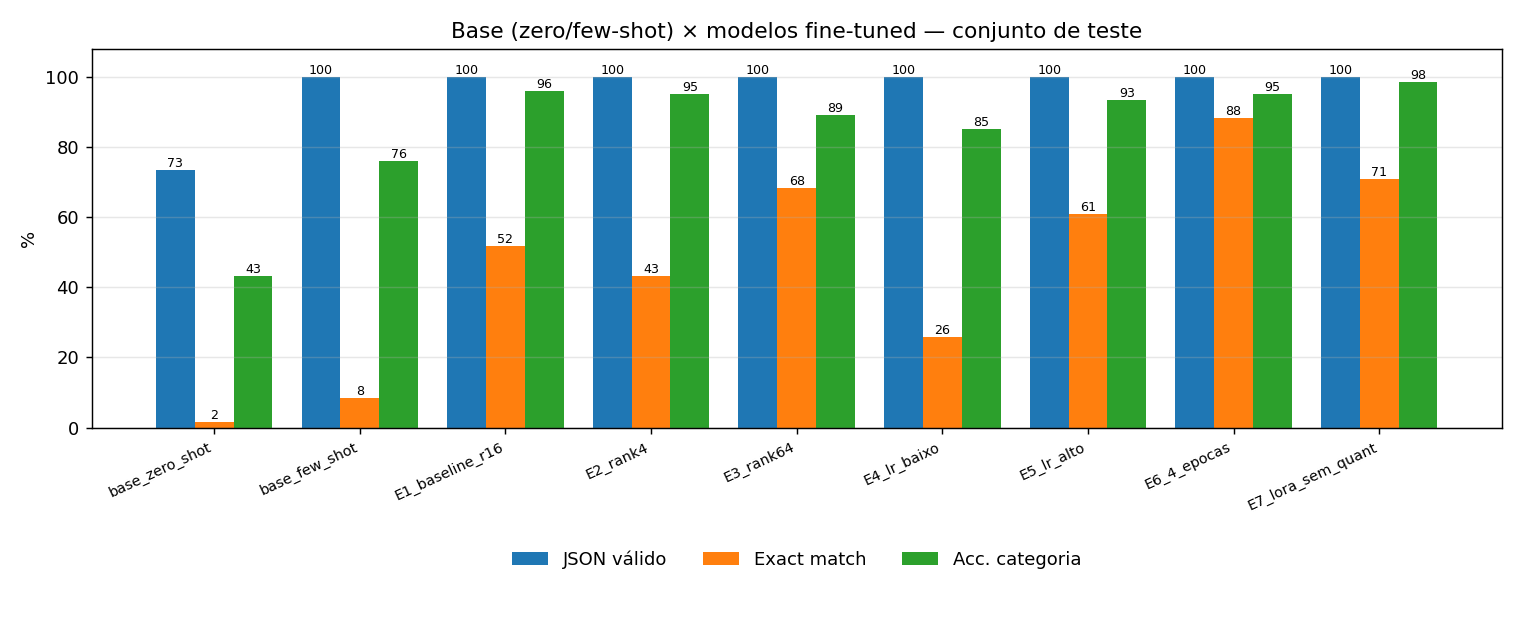

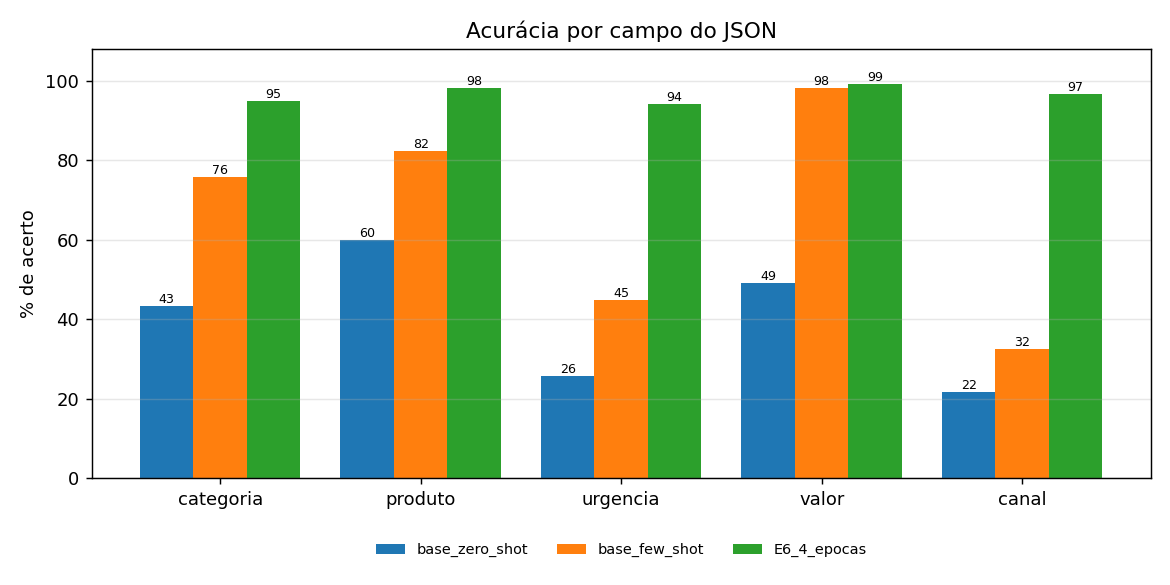

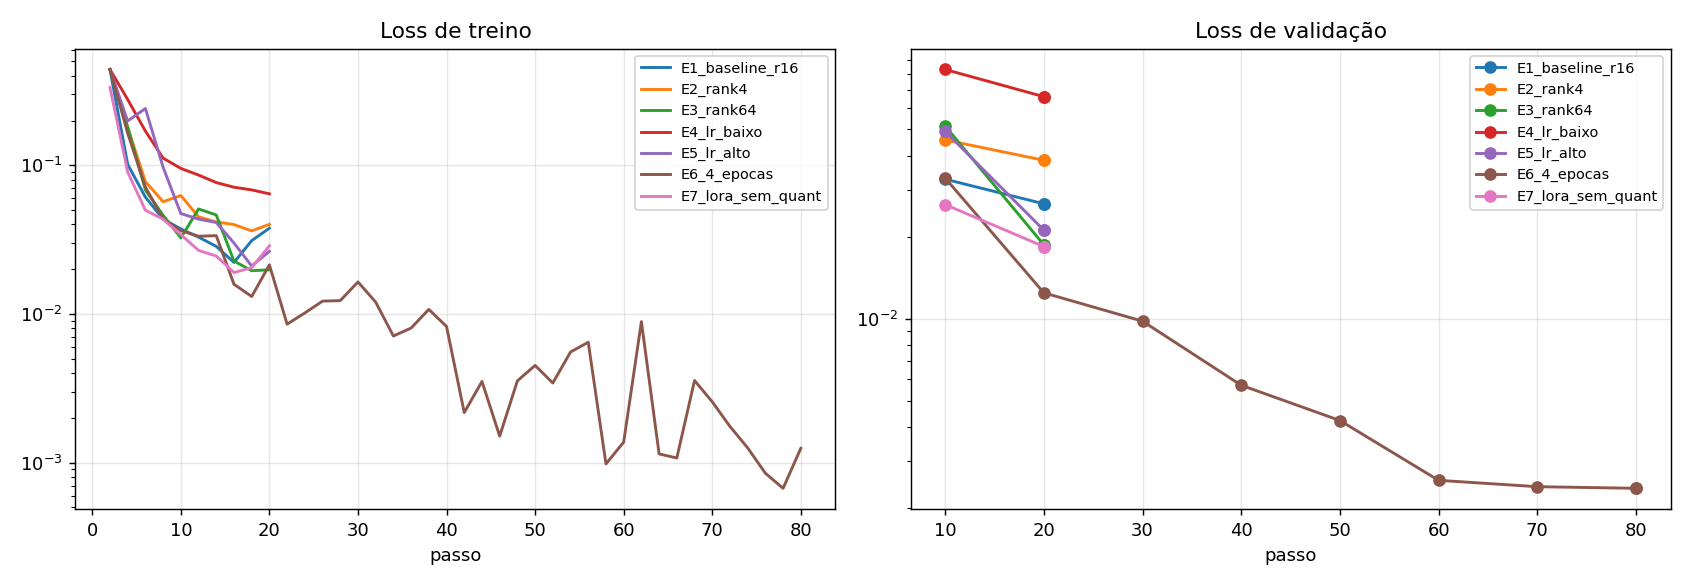

In [23]:
from IPython.display import Markdown, Image, display

display(Markdown(open("results/tabela_experimentos.md", encoding="utf-8").read()))
for img in ["comparativo_modelos.png", "acuracia_por_campo.png", "curvas_loss.png"]:
    if os.path.exists(f"docs/img/{img}"):
        display(Image(f"docs/img/{img}"))

In [24]:
texto = open("results/RESULTADOS.md", encoding="utf-8").read()
display(Markdown(texto.split("### Análise")[1].split("![")[0]))



- **Observação:** experimentos rodados em modo reduzido (320 exemplos de treino, 1 época(s), 320 exemplos de treino, 4 época(s)) por limite de tempo de GPU; com o dataset completo os números tendem a subir.
- **Melhor configuração:** `E6_4_epocas` com **88.3%** de exact match (todos os 5 campos corretos) e 100.0% de JSON válido.
- Ganho sobre `base_zero_shot`: **+86.7 p.p.** de exact match (1.7% → 88.3%).
- Ganho sobre `base_few_shot`: **+80.0 p.p.** de exact match (8.3% → 88.3%).
- **Efeito do rank LoRA:** r=4: 43.3% EM, 4.6M params treináveis; r=16: 51.7% EM, 18.5M params treináveis; r=64: 68.3% EM, 73.9M params treináveis.
- **Efeito da learning rate:** lr=2e-5: eval loss 0.066, EM 25.8%; lr=2e-4: eval loss 0.0266, EM 51.7%; lr=1e-3: eval loss 0.0213, EM 60.8%.
- **4 épocas:** a loss de validação não subiu de forma relevante (mín 0.0024, final 0.0024); sem sinal claro de overfitting.
- **QLoRA 4-bit × LoRA sem quantização:** VRAM 7.45 GB × 8.28 GB; tempo 2.2 × 1.7 min; EM 51.7% × 70.8%.
- **Generalização:** no melhor modelo, EM em frases de templates vistos no treino = 92.9%; em templates **nunca vistos** = 84.4%.
- **Análise de erro do melhor modelo:** erros por campo: urgencia = 7, categoria = 6, canal = 4, produto = 2, valor = 1.
- Confusões de categoria mais comuns: `cartao_bloqueado → cobranca_indevida` (2x); `compra_nao_reconhecida → cobranca_indevida` (2x); `acesso_bloqueado → segunda_via_boleto` (1x).



In [2]:
import platform, os
print(platform.system())
print(os.path.exists("/content/llm-triagem-chamados/runs"))
%cd /content/llm-triagem-chamados
!ls results runs

Linux
False
[Errno 2] No such file or directory: '/content/llm-triagem-chamados'
/content
ls: cannot access 'results': No such file or directory
ls: cannot access 'runs': No such file or directory


In [ ]:
!python src/app.py --share

Loading weights: 100% 338/338 [00:04<00:00, 77.71it/s] 
Modelo: Qwen/Qwen2.5-1.5B-Instruct | adapter: /content/llm-triagem-chamados/runs/E6_4_epocas/adapter | GPU: Tesla T4
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://671de50e3865e22f5c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
